# EDA: Student Mental Health Survey

*Kiera Wilson — SEIS 631*

**This document is for:** A reader interested in patterns in anxiety and depression screening scores across sex and state.


Dataset/source page: https://bsos-data.umd.edu/dataset/social-media-and-mental-health/resource/047eac54-fcce-406a-89e4-9dde700f1703?inner_span=True

## Setup and loading

Import the libraries used in this notebook and read the supplied CSV file. The filename should match the file saved beside this notebook.

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
# Put your downloaded Kaggle file(s) in this repository's directory.
# The .gitignore keeps data out of Git -- don't fight it.
df = pd.read_csv("mental_health2425v8in.csv")   # <-- swap in your filename
df.shape

(579, 118)

In [44]:
# print the first five rows to see the dataset
df.head()

,year_1,state_1,general_health,phq9_1,phq9_2,phq9_3,phq9_4,phq9_5,phq9_6,phq9_7,...,acha_12months_any_comp,sex,fulltime,international,race_1,race_2,race_3,race_4,race_5,race_6
0,2000,MD,Very Good,Several days,Several days,Not at all,Several days,Not at all,Not at all,More than half of the days,...,2,Female,Yes,No,NaN,NaN,NaN,Asian or Pacific Islander,NaN,NaN
1,2001,SC,Good,More than half of the days,More than half of the days,Nearly every day,Nearly every day,Nearly every day,Several days,Nearly every day,...,0,Female,Yes,No,NaN,NaN,NaN,Asian or Pacific Islander,NaN,NaN
2,1999,NJ,Good,Several days,Several days,More than half of the days,More than half of the days,Several days,Several days,Several days,...,2,Female,Yes,No,NaN,NaN,Hispanic or Latino,Asian or Pacific Islander,NaN,NaN
3,1998,NY,Good,Several days,Several days,Nearly every day,Nearly every day,Not at all,Several days,Several days,...,2,Female,Yes,No,White - not Hispanic (includes Middle Eastern),NaN,NaN,NaN,NaN,NaN
4,2000,PA,Very Good,Not at all,Several days,Several days,Several days,Several days,Several days,Several days,...,5,Female,Yes,No,White - not Hispanic (includes Middle Eastern),NaN,NaN,NaN,NaN,NaN


There are 118 columns in this dataset. The extensiveness of the columns comes from the fact that many of them represent responses from students on a survey.

The **PHQ-9** (a 9 question self reporting health questionare used to screen for depression) has 20 total columns related to the responses and a numerical encoding of the responses. 

The **GAD-7** (a 7 question self reporting health questionare used to screen for anxiety) has a total of 16 columns related to the responses and a numerical encoding of the responses. 

To make analysis easier I am going to filter out all the columns besides the ones I will be looking at for relationships between mental health, sex, and state.


In [45]:
columns_to_keep = [
    "year_1",
    "state_1",
    "sex",
    "fulltime",
    "international",
    "general_health",
    "phq9_COMP",
    "phq9_severity",
    "gad7_COMP",
    "gad7_severity",
]

df_filtered = df[columns_to_keep].copy()

# Save as a separate file so the original dataset stays unchanged
df_filtered.to_csv("mental_health_summary.csv", index=False)

### Clean up

One clean up item I am going to do right away is cleaning up leading and trailing spaces and convert the year_1 column to an integrer so it is easier to work with later.

In [46]:
# convert the year one variable to a  type 
df_filtered["year_1"] = pd.to_numeric(df_filtered["year_1"], errors="coerce").astype("Int64")

print(df_filtered["year_1"].dtype)
df_filtered["year_1"].describe()

# remove leading and trailing whitespace from column names
df_filtered.columns = df_filtered.columns.str.strip()

# print the type of each variable
print("Types for each variable: ")
print(df_filtered.dtypes)
df_filtered.head()


Int64
Types for each variable: 
year_1            Int64
state_1             str
sex                 str
fulltime            str
international       str
general_health      str
phq9_COMP         int64
phq9_severity       str
gad7_COMP         int64
gad7_severity       str
dtype: object


,year_1,state_1,sex,fulltime,international,general_health,phq9_COMP,phq9_severity,gad7_COMP,gad7_severity
0,2000,MD,Female,Yes,No,Very Good,6,Mild depression,0,minimal anxiety
1,2001,SC,Female,Yes,No,Good,19,Moderately severe depression,4,minimal anxiety
2,1999,NJ,Female,Yes,No,Good,10,Moderate depression,9,mild anxiety
3,1998,NY,Female,Yes,No,Good,11,Moderate depression,10,moderate anxiety
4,2000,PA,Female,Yes,No,Very Good,6,Mild depression,18,severe anxiety


## 1. Provenance & scope

### Origin of the data
The dats set is from the University of Maryland BSOS data library. The data was collected via a student survey from students across 48 U.S. states who were born between 1971-2003. The data includes PHQ-9 depression and GAD-7 anxiety screening responses, general health, state, sex, and other demographic/health fields.


### What one row represents
The rows represents individual survey respondents, their demopraphic information as well as their responses to the GAD and PHQ survey.

In [47]:
# loop through print the columns of the dataframe  
for col in df_filtered.columns:
    print(col)

year_1
state_1
sex
fulltime
international
general_health
phq9_COMP
phq9_severity
gad7_COMP
gad7_severity


### Data coverage (time, geography, population)
The state field contains 48 distinct state codes. All respondents are students and the 'full time' column indicares wheter they are full time in school or not.

In [48]:
print(f"Rows: {df_filtered.shape[0]:,}; columns: {df_filtered.shape[1]:,}")
print("Distinct state codes:", df_filtered["state_1"].nunique())
print("Most represented states:")
display(df_filtered["state_1"].value_counts().head(10))
print("Sex counts:")
display(df_filtered["sex"].value_counts(dropna=False))

Rows: 579; columns: 10
Distinct state codes: 48
Most represented states:


state_1
CA    76
TX    61
NY    51
FL    37
PA    33
OH    31
IL    23
VA    23
GA    21
NC    16
Name: count, dtype: int64

Sex counts:


sex
Female    393
Male      186
Name: count, dtype: int64

## 2. Structure & quality

### Important variables and their types
The primary overall measures are `phq9_COMP` (PHQ-9 depression total, numeric score) and `gad7_COMP` (GAD-7 anxiety total, numeric score). The related `phq9_severity` and `gad7_severity` columns are categorical interpretations of those scores (tables below describe how the numeric score is associated with a category). `sex` and `state_1` are categorical variables. `general_health` is another self-reported categorical measure. The code block below shows the possible values for general health ranging from poor to excellent. We see most of the respondents answered 'good', 'very good', or 'fair' with far fewer choosing 'excellent' or 'poor'. This could be explained by a central tendency bias where respondents are more likely to choose middle options rather than the extreme ends.

In [49]:
# look at possible general health values
df["general_health"].value_counts(dropna=False)

general_health
Good         227
Very Good    178
Fair         103
Excellent     42
Poor          29
Name: count, dtype: int64

 
#### PHQ-9 depression severity scale
Based on the individual `phq9_XNUM` responses, the PHQ-9 composite score (`phq9_COMP`) is calculated. The corresponding severity label is stored in `phq9_severity`.

| PHQ-9 total | Severity |
| --- | --- |
| 0-4 | Minimal depression |
| 5-9 | Mild depression |
| 10-14 | Moderate depression |
| 15-19 | Moderately severe depression |
| 20-27 | Severe depression |

#### GAD-7 anxiety severity scale
The GAD-7 composite score (`gad7_COMP`) is calculated from the seven GAD-7 item responses. Its severity label is stored in `gad7_severity`. The standard score bands are:

| GAD-7 total | Severity |
| --- | --- |
| 0-4 | Minimal anxiety |
| 5-9 | Mild anxiety |
| 10-14 | Moderate anxiety |
| 15-21 | Severe anxiety |

The data set notes that these are screening-score categories, not clinical diagnoses. The PHQ-9 and GAD-7 use different score ranges and should be interpreted separately.


In [50]:
# print labels for severity of each test
print("PHQ-9 severity labels:")
display(df["phq9_severity"].value_counts(dropna=False))
print("GAD-7 severity labels:")
display(df["gad7_severity"].value_counts(dropna=False))

PHQ-9 severity labels:


phq9_severity
Mild depression                 170
Moderate depression             147
Minimal depression              146
Moderately severe depression     78
Severe depression                38
Name: count, dtype: int64

GAD-7 severity labels:


gad7_severity
mild anxiety        191
minimal anxiety     172
moderate anxiety    123
severe anxiety       93
Name: count, dtype: int64

### Missing values and value checks
To start we will look at if there are any duplicate rows and which columns are missing values.

In [51]:
print("Duplicate rows:", df_filtered.duplicated().sum())

print("Missing values across columns:")
display(df_filtered.isna().sum())

#print("Sex counts:")
#display(df_filtered["sex"].value_counts(dropna=False))

#print("State counts, smallest first:")
#display(df_filtered["state_1"].value_counts(dropna=False).sort_values().head(15))


Duplicate rows: 1
Missing values across columns:


year_1            0
state_1           0
sex               0
fulltime          0
international     1
general_health    0
phq9_COMP         0
phq9_severity     0
gad7_COMP         0
gad7_severity     0
dtype: int64

The output shows us that there is 1 duplicate row which we will filter out. Additionally there is only one missing value in the international column. Since we won't be filtering or looking at relationships based on international identification I wont be filtering out or impuning an answer instead.

In [52]:
# Drop the duplicate, keeping the first occurrence
df_filtered = df_filtered.drop_duplicates(keep="first").reset_index(drop=True)

print("Shape after dropping duplicate:", df_filtered.shape)


Shape after dropping duplicate: (578, 10)


This confirms that the duplate was dropped and we see one less row of data.

Next I want to look at the PHQ and GAD scores to make sure the composites are within the range of the actual scales.

In [53]:
# value check PHQ and GAD scores 
display(df_filtered[["phq9_COMP", "gad7_COMP"]].describe())

print("PHQ-9 scores outside 0-27:", ((df["phq9_COMP"] < 0) | (df["phq9_COMP"] > 27)).sum())
print("GAD-7 scores outside 0-21:", ((df["gad7_COMP"] < 0) | (df["gad7_COMP"] > 21)).sum())



,phq9_COMP,gad7_COMP
count,578.000000,578.000000
mean,9.378893,8.323529
std,6.204491,5.689922
min,0.000000,0.000000
25%,4.000000,4.000000
50%,9.000000,7.000000
75%,13.000000,12.000000
max,27.000000,21.000000


PHQ-9 scores outside 0-27: 0
GAD-7 scores outside 0-21: 0


Here we can see that all the composite values are within the 0-27 and 0-21 scales. The mean of PHQ is 9.37 (mild depression) and the mean of GAD is 8.32 (mild anxiety).

### Variable transformations
Earlier in this note book we removed any trailing spaces and converted the year column to an integer, we wont be doing any further transformations on the data.

## 3. Distributions

### PHQ-9 depression and GAD-7 anxiety scores
`phq9_COMP` and `gad7_COMP` are the overall numeric screening totals and the most important variables in this dataframe.

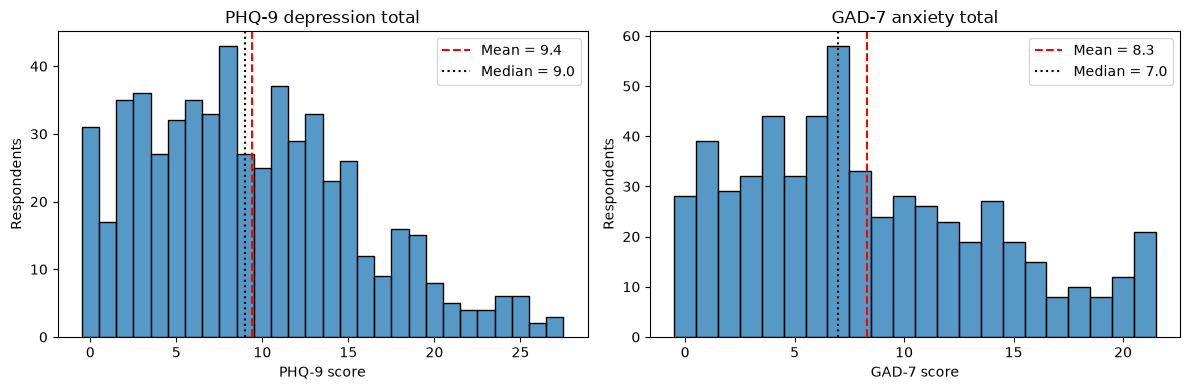

In [54]:
# Display distribution for PHQ and GAD
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="phq9_COMP", discrete=True, ax=axes[0])
phq9_mean = df["phq9_COMP"].mean()
phq9_median = df["phq9_COMP"].median()
axes[0].axvline(phq9_mean, color="red", linestyle="--", label=f"Mean = {phq9_mean:.1f}")
axes[0].axvline(phq9_median, color="black", linestyle=":", label=f"Median = {phq9_median:.1f}")
axes[0].set(title="PHQ-9 depression total", xlabel="PHQ-9 score", ylabel="Respondents")
axes[0].legend()

sns.histplot(data=df, x="gad7_COMP", discrete=True, ax=axes[1])
gad7_mean = df["gad7_COMP"].mean()
gad7_median = df["gad7_COMP"].median()
axes[1].axvline(gad7_mean, color="red", linestyle="--", label=f"Mean = {gad7_mean:.1f}")
axes[1].axvline(gad7_median, color="black", linestyle=":", label=f"Median = {gad7_median:.1f}")
axes[1].set(title="GAD-7 anxiety total", xlabel="GAD-7 score", ylabel="Respondents")
axes[1].legend()

plt.tight_layout()
plt.show()


The histograms above show us the distripution of the PHQ and GAD variables. The x axis represents the test scores respectively and the y axis represents the number of respondents who had that score.

**PHQ** The distribution for PHQ is unimodal with a right skew. The values span from 0 to 17 on the chart. the mean is 9.4 and we see the peak slightly before that at arouns 8.5. the median is slightly lower at 9, indicating that the few values that are higher are pulling the mean up to be a bit higher. 

**GAD** The distribution of the GAD is also right skewed and unimodal with a peak at its median at 7. The mean is slightly higher at 8.3. We do see one bar at the far right of the GAD plot that comes a bit higher up indicating that there are several respondends in the severe anxiety category who are pulling the mean up.

In [55]:
# look at summary statistics for PHQ and GAD 
display(df_filtered[["phq9_COMP", "gad7_COMP"]].describe())


,phq9_COMP,gad7_COMP
count,578.000000,578.000000
mean,9.378893,8.323529
std,6.204491,5.689922
min,0.000000,0.000000
25%,4.000000,4.000000
50%,9.000000,7.000000
75%,13.000000,12.000000
max,27.000000,21.000000


When looking at the summary of the statisics we see that the middle 50% of the PHQ scores land between 4 and 13 (Mild to moderate depression). For GAD 50% of the scores land between 4 and 12 (Mild to moderate anxiety).

Next I want to look at sex. I want to understand how many people from each gender answered this survey as this is a key relationship I want to look at later. 

,sex,count,percent
0,Female,393,67.9
1,Male,186,32.1


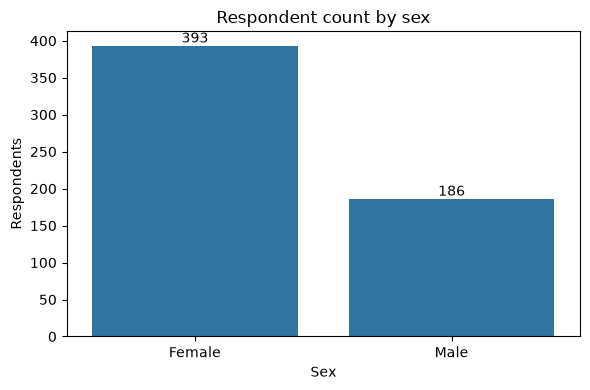

In [56]:
# look at sex distribution in the data frame
sex_counts = df["sex"].value_counts(dropna=False).rename_axis("sex").reset_index(name="count")
sex_counts["percent"] = (sex_counts["count"] / sex_counts["count"].sum() * 100).round(1)
display(sex_counts)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="sex", order=sex_counts["sex"], ax=ax)
ax.set(title="Respondent count by sex", xlabel="Sex", ylabel="Respondents")
for i, count in enumerate(sex_counts["count"]):
    ax.text(i, count, str(count), ha="center", va="bottom")
plt.tight_layout()
plt.show()

The plot above shows that we have 393 female respondents and 186 male respondents. This shouldnt cause issues with analysis but it will be important to keep in mind that there are more than twice as many female respondents than male. We should keep an eye out for how this could impact analysis later on.

## 4. Relationships

### Do scores differ by sex?

One relationship I want to look into is if there is a higher rate of depression or anxiety in one gender group or the other. I am going to start by looking at a plot in the different scores between the genders.

,respondents,phq9_mean,phq9_median,gad7_mean,gad7_median
sex,,,,,
Female,392,9.60,9.0,9.21,8.0
Male,186,8.91,8.0,6.46,5.0


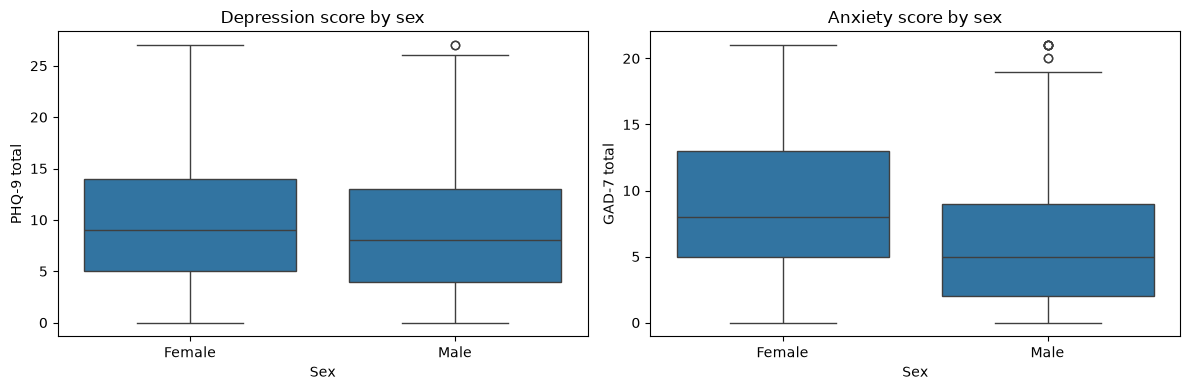

In [57]:
sex_summary = df_filtered.groupby("sex", dropna=False).agg(
    respondents=("sex", "size"),
    phq9_mean=("phq9_COMP", "mean"),
    phq9_median=("phq9_COMP", "median"),
    gad7_mean=("gad7_COMP", "mean"),
    gad7_median=("gad7_COMP", "median"),
).round(2)
display(sex_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="sex", y="phq9_COMP", ax=axes[0])
axes[0].set(title="Depression score by sex", xlabel="Sex", ylabel="PHQ-9 total")
sns.boxplot(data=df, x="sex", y="gad7_COMP", ax=axes[1])
axes[1].set(title="Anxiety score by sex", xlabel="Sex", ylabel="GAD-7 total")
plt.tight_layout()
plt.show()

The visualization above shows the the differences in the distribution of comprehensive depression and anxiety scores between male and female respondents. 

The plot on the left shows the difference in depression scores. Females have a median of 9 and a mean of 9.6 while males have a slightly lower median at 8 and a mean at 8.91. 

The plot on the right shows the differences in depression scores. Females have a median of 8 with a mean of 9.21. The slightly higher mean points to there being a cluster of high scores in the questionare pulling the mean higher. For males, the median is much lower at 5 with a mean at 6.46. 

In both plots we see that females have generally higher scores for depression and anxiety. 

To look at this in another way I am going to use a density plot. 


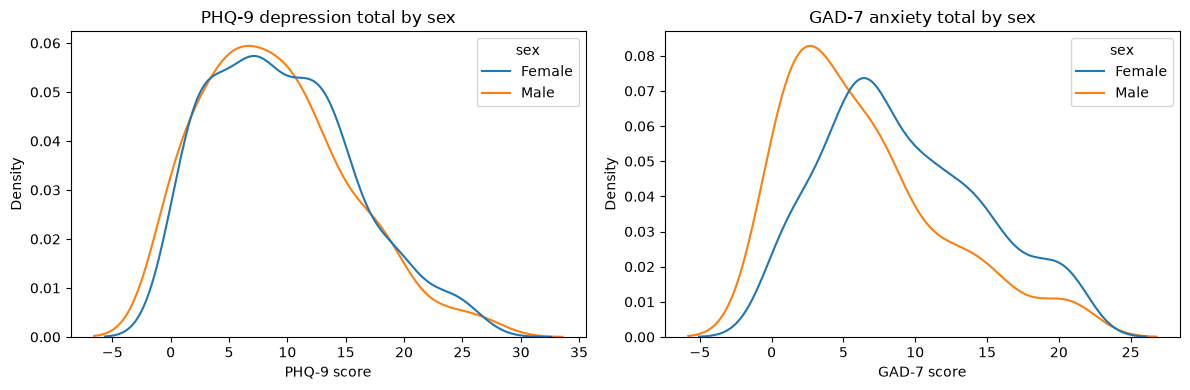

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(data=df, x="phq9_COMP", hue="sex", common_norm=False, ax=axes[0])
axes[0].set(title="PHQ-9 depression total by sex", xlabel="PHQ-9 score", ylabel="Density")

sns.kdeplot(data=df, x="gad7_COMP", hue="sex", common_norm=False, ax=axes[1])
axes[1].set(title="GAD-7 anxiety total by sex", xlabel="GAD-7 score", ylabel="Density")

plt.tight_layout()
plt.show()


What stands out to me here is how simular the distribution of male and female PHQ scores look in the plot on the left. The two lines follow eachother closely with the female scores straying slightly to the right around 15. 

For GAD we see that female scores are further to the right for the entirety of the plot, indicating that scores are higher for females.

## 5. Readiness

Before presenting this analysis, verify the survey name, collection period, respondent eligibility, sampling/recruitment method, and definitions of `year_1`, `sex`, and `state_1` from the source documentation. Check whether `N/A` values in other columns are literal text or missing responses. Consider whether 579 respondents and uneven state counts support the comparisons you want to make.

This dataset can support descriptive summaries of PHQ-9 and GAD-7 screening scores and exploratory comparisons by recorded sex and state. It cannot answer a social-media-use question because no social-media-use variable is present. Do not describe the screening scores as diagnoses or interpret associations as causal effects.

## 6. Your questions (14, 15, …)

### What bias might be present?
The survey itself also introduces a central tendancy bias. Respondents may be more likely to choose options in the middle rather than the extreme, even if it fits their situation better. This could contribute to us having results that seem more mild than they are. There could also be response fatigue as respondents are answering 15 plus mental health questions in a row they may tend to just answer without thinking more deeply about what their actual response is.

### What question can this dataset answer instead?
Since this data observed and not an experiement we cant make difinitve statements about mental health and how it affects genders. We could answer questions about how self reported anxiety scores differ across genders. We still need to be careful about drawing any hard conclusions about how likely each gender is to self report on their mental health.

### What additional data would help?
I would have liked to be able to link social media usage with mental health score like in this data. Unfortunatly this data set included mostly demographic data along with mental health data rather than any social media usage. 

## Reflection

After completing the analysis, reflect on what was confusing and how you resolved it, how AI or other help supported the work, one suggestion you verified or corrected, what you can now explain independently, how long the work took, and what questions remain. In particular, describe how you adjusted the original social-media hypothesis after checking the actual variables.

I used AI mainly to help with visual representations of the data. After completing the actual EDA assigment in the past I had a pretty good idea of what analysis I needed to do and how to talk about the visualization. I think there are maybe more relationships I could look into in this data frame but the male vs female comprehensive scores seemed like it would be the most promissing. I might continue to look for relationships while working on the rest of the assignment.